
## 1. Mục tiêu
Kiểm tra phương sai, tương quan nội bộ giữa 27 câu hỏi và thử nghiệm thuật toán lựa chọn đặc trưng (SelectKBest) trong training fold nội bộ.


In [1]:
from pathlib import Path
import sys,hashlib
import pandas as pd
import numpy as np
from IPython.display import display
assert sys.version_info[:2] == (3,14)
ROOT = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'dataLabanAI.xlsx').is_file())
workbook_path = ROOT/'dataLabanAI.xlsx'
sha_before = hashlib.sha256(workbook_path.read_bytes()).hexdigest()
sha_notebook00 = 'c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8'
assert sha_before == sha_notebook00, 'Workbook khác phiên bản Notebook 00; cần audit lại trước xử lý.'
excel = pd.ExcelFile(workbook_path)
assert excel.sheet_names == ['THONG_TIN','RIASEC_27','SO_THICH_6','CODEBOOK_33','KIEM_TRA']
raw_riasec = pd.read_excel(excel,sheet_name='RIASEC_27')
raw_q5 = pd.read_excel(excel,sheet_name='SO_THICH_6')
raw_codebook = pd.read_excel(excel,sheet_name='CODEBOOK_33')
# Bản sao gốc dùng đối chiếu, không thay đổi các DataFrame này.
original_riasec = raw_riasec.copy(deep=True)
original_q5 = raw_q5.copy(deep=True)
original_codebook = raw_codebook.copy(deep=True)
print('Python:',sys.version,'; Interpreter:',sys.executable)
print('SHA-256:',sha_before)
display(pd.DataFrame([{'Sheet':name,'Số dòng':len(frame),'Số cột':frame.shape[1]}
    for name,frame in [('RIASEC_27',raw_riasec),('SO_THICH_6',raw_q5),('CODEBOOK_33',raw_codebook)]]))


Python: 3.14.7 (tags/v3.14.7:823f032, Aug  5 2026, 10:51:32) [MSC v.1944 64 bit (AMD64)] ; Interpreter: C:\Users\DELL\AppData\Local\Programs\Python\Python314\python.exe
SHA-256: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8
         Sheet  Số dòng  Số cột
0    RIASEC_27     4910      28
1   SO_THICH_6     4910       7
2  CODEBOOK_33       33       5


In [2]:
question_columns = ['R1','I1','A1','R2','I2','A2','S1','S2','R3','A3','S3','E1','R4','S4','E2','R5','I3','A4','E3','I4','A5','E4','C1','E5','C2','C3','C4']
q5_columns = ['Q5_LikeRe','Q5_LikeIn','Q5_LikeAr','Q5_LikeSo','Q5_LikeEn','Q5_LikeCo']
survey_columns = question_columns+q5_columns
assert raw_riasec.shape == (4910,28) and raw_q5.shape == (4910,7)
assert list(raw_riasec.columns) == ['SOURCE_ROW']+question_columns
assert list(raw_q5.columns) == ['SOURCE_ROW']+q5_columns
assert raw_codebook.MA_COT.is_unique and raw_codebook.MA_COT.tolist() == survey_columns
assert raw_codebook.iloc[:27]['LOAI'].eq('RIASEC rút gọn').all()
assert raw_codebook.iloc[27:]['LOAI'].eq('Mức ưa thích nhóm nghề').all()
assert raw_codebook.iloc[:27]['THANG_DIEM_GOC'].nunique()==1
assert raw_codebook.iloc[27:]['THANG_DIEM_GOC'].nunique()==1
for frame in [raw_riasec,raw_q5]:
    assert frame.SOURCE_ROW.notna().all() and frame.SOURCE_ROW.is_unique
    assert pd.api.types.is_integer_dtype(frame.SOURCE_ROW)
assert set(raw_riasec.SOURCE_ROW) == set(raw_q5.SOURCE_ROW)
merged = raw_riasec.merge(raw_q5,on='SOURCE_ROW',how='outer',validate='one_to_one',indicator=True,sort=False)
display(merged['_merge'].value_counts().rename('Số dòng sau ghép').to_frame())
assert len(merged) == len(raw_riasec) == len(raw_q5) == 4910
assert merged['_merge'].eq('both').all()
merged = merged.drop(columns='_merge').set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW].reset_index()
assert merged.SOURCE_ROW.equals(raw_riasec.SOURCE_ROW)
assert merged[question_columns].equals(raw_riasec[question_columns])
assert merged[q5_columns].equals(raw_q5.set_index('SOURCE_ROW').loc[raw_riasec.SOURCE_ROW,q5_columns].reset_index(drop=True))
df_original = merged.copy(deep=True)
raw_survey = df_original[survey_columns].copy()
print('PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.')


PASS: ghép một-một, không mất/thêm dòng, giữ thứ tự nguồn và 33 biến.


            Số dòng sau ghép
_merge                      
both                    4910
left_only                  0
right_only                 0

In [3]:
type_rows = []
for col in survey_columns:
    values = raw_survey[col]
    numeric = pd.to_numeric(values,errors='coerce')
    is_numeric_cell = values.map(lambda value:isinstance(value,(int,float,np.integer,np.floating)) and not isinstance(value,(bool,np.bool_)))
    valid = is_numeric_cell & numeric.isin([1,2,3,4,5])
    type_rows.append({'Cột':col,'dtype gốc':str(values.dtype),'Thiếu':int(values.isna().sum()),
        'Sai kiểu hoặc ngoài miền':int((values.notna() & ~valid).sum())})
type_check = pd.DataFrame(type_rows).set_index('Cột')
display(type_check)
if type_check['Thiếu'].sum() or type_check['Sai kiểu hoặc ngoài miền'].sum():
    raise RuntimeError('Có giá trị sai/thiếu; dừng để quyết định xử lý, không tự sửa.')
survey_int = raw_survey.astype('int64')
assert np.array_equal(survey_int.to_numpy(),raw_survey.to_numpy())
assert survey_int.isin(range(1,6)).all().all()
assert all(pd.api.types.is_integer_dtype(dtype) for dtype in survey_int.dtypes)
answers27 = survey_int[question_columns].copy()
preferences6 = survey_int[q5_columns].copy()
print('PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.')


PASS: đủ 33 biến, không thiếu/sai kiểu/ngoài miền; chuyển int64 không đổi giá trị.


          dtype gốc  Thiếu  Sai kiểu hoặc ngoài miền
Cột                                                 
R1            int64      0                         0
I1            int64      0                         0
A1            int64      0                         0
R2            int64      0                         0
I2            int64      0                         0
A2            int64      0                         0
S1            int64      0                         0
S2            int64      0                         0
R3            int64      0                         0
A3            int64      0                         0
S3            int64      0                         0
E1            int64      0                         0
R4            int64      0                         0
S4            int64      0                         0
E2            int64      0                         0
R5            int64      0                         0
I3            int64      0                    

In [4]:
from sklearn.model_selection import GroupShuffleSplit
import sklearn
X = answers27.copy()
y = preferences6.copy()
groups = pd.Series(pd.factorize(pd.MultiIndex.from_frame(X),sort=False)[0],index=X.index,name='group_X27')
splitter = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
train_pos,test_pos = next(splitter.split(X,groups=groups))
X_train,X_test = X.iloc[train_pos].copy(),X.iloc[test_pos].copy()
y_train,y_test = y.iloc[train_pos].copy(),y.iloc[test_pos].copy()
groups_train,groups_test = groups.iloc[train_pos].copy(),groups.iloc[test_pos].copy()
assert X_train.shape==(3963,27) and X_test.shape==(947,27)
assert y_train.shape==(3963,6) and y_test.shape==(947,6)
assert groups_train.nunique()==3568 and groups_test.nunique()==892
assert X.index.is_unique and X_train.index.intersection(X_test.index).empty
assert len(X_train)+len(X_test)==4910
assert set(X_train.index)|set(X_test.index)==set(X.index)
assert set(groups_train).isdisjoint(groups_test)
assert set(X_train.itertuples(index=False,name=None)).isdisjoint(X_test.itertuples(index=False,name=None))
assert list(X_train.columns)==list(X_test.columns)==question_columns
assert list(y_train.columns)==list(y_test.columns)==q5_columns
assert y_train.index.equals(X_train.index) and y_test.index.equals(X_test.index)
assert y_train.equals(y.loc[X_train.index]) and y_test.equals(y.loc[X_test.index])
train_index_sha256=hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()
test_index_sha256=hashlib.sha256(np.asarray(X_test.index,dtype='<i8').tobytes()).hexdigest()
assert train_index_sha256=='471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d'
assert test_index_sha256=='92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b'
print('PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.')
print('SHA index Train/Test:',train_index_sha256,test_index_sha256)
print('pandas/numpy/sklearn:',pd.__version__,np.__version__,sklearn.__version__)
# Giữ codebook và đường dẫn/hash; bỏ các DataFrame có phản hồi Test/toàn tập.
del X_test,y_test,groups_test,X,y,groups,train_pos,test_pos
# Các bản sao toàn tập từ bước đọc/làm sạch cũng không dùng cho nghiên cứu đặc trưng.
del raw_riasec,raw_q5,original_riasec,original_q5,merged,df_original,raw_survey,survey_int,answers27,preferences6

# Bỏ cả alias còn lại của các vòng kiểm tra kiểu/khóa.
del frame,values,numeric,is_numeric_cell,valid


PASS: đúng index Notebook 02; Train 3963×27, 3568 group; Test 947×27, 892 group; y có 6 cột.
SHA index Train/Test: 471fecbbc5d665e949eae03bcdebedc996044f30136a56d8b1d698ad3d7e2d4d 92594157a2b76a9d59f375dd14bf6617cd5b58232f368b86688e17c011d8392b
pandas/numpy/sklearn: 3.0.6 2.5.3 1.9.1


## 2. Kiểm tra phương sai đặc trưng trên Train
Xác minh phương sai của 27 câu hỏi Likert; kiểm tra xem có cột hằng số hoặc phương sai cực thấp hay không.


In [5]:
assert X_train.shape==(3963,27) and y_train.shape==(3963,6)
assert list(X_train.columns)==question_columns and list(y_train.columns)==q5_columns
assert X_train.index.equals(y_train.index) and X_train.index.equals(groups_train.index)
assert not set(q5_columns+['SOURCE_ROW']).intersection(X_train.columns)
X_snapshot=X_train.copy(deep=True)
y_snapshot=y_train.copy(deep=True)
item_counts=pd.DataFrame({col:X_train[col].value_counts().reindex(range(1,6),fill_value=0) for col in question_columns}).T
item_rates=item_counts/len(X_train)*100
variance_table=pd.DataFrame({'Variance (ddof=0)':X_train.var(ddof=0),'SD (ddof=1)':X_train.std(ddof=1),
    'Số mức':X_train.nunique(),'Tỷ lệ mức phổ biến (%)':item_rates.max(axis=1)})
constant_items=variance_table.index[variance_table['Variance (ddof=0)'].eq(0)].tolist()
low_items=variance_table.index[variance_table['Variance (ddof=0)']<.25].tolist()
near_constant_items=variance_table.index[variance_table['Tỷ lệ mức phổ biến (%)']>=80].tolist()
display(variance_table.round(6))
display(item_rates.rename(columns=lambda level:f'Mức {level} (%)').round(4))
print('Cột hằng:',constant_items,'; variance <0,25:',low_items,'; một mức >=80%:',near_constant_items)
print('SD min/max thực tế:',variance_table['SD (ddof=1)'].min(),variance_table['SD (ddof=1)'].max())
# So sánh kết quả thực tính với số làm tròn được báo ở Notebook 03.
assert np.isclose(variance_table['SD (ddof=1)'].min(),1.0146,atol=5e-5)
assert np.isclose(variance_table['SD (ddof=1)'].max(),1.2210,atol=5e-5)
print('Khớp Notebook 03: các câu đều có biến thiên; không cần loại theo cột hằng/gần hằng khi các danh sách trên rỗng.')


Cột hằng: [] ; variance <0,25: [] ; một mức >=80%: []
SD min/max thực tế: 1.0146299428845489 1.2210328656095728
Khớp Notebook 03: các câu đều có biến thiên; không cần loại theo cột hằng/gần hằng khi các danh sách trên rỗng.


    Variance (ddof=0)  SD (ddof=1)  Số mức  Tỷ lệ mức phổ biến (%)
R1           1.227776     1.108190       5               33.080999
I1           1.241880     1.114537       5               36.310876
A1           1.275786     1.129650       5               35.225839
R2           1.134250     1.065146       5               35.427706
I2           1.178673     1.085804       5               34.418370
A2           1.183249     1.087910       5               32.929599
S1           1.288973     1.135473       5               33.484734
S2           1.255029     1.120422       5               36.134242
R3           1.220892     1.105079       5               32.853899
A3           1.490545     1.221033       5               31.314661
S3           1.285476     1.133931       5               33.610901
E1           1.250654     1.118467       5               32.248297
R4           1.084288     1.041423       5               33.409034
S4           1.324550     1.151036       5               35.32

    Mức 1 (%)  Mức 2 (%)  Mức 3 (%)  Mức 4 (%)  Mức 5 (%)
R1    19.6316    29.1951    33.0810    12.4401     5.6523
I1    17.8400    23.9213    36.3109    16.1998     5.7280
A1    14.2821    24.5773    35.2258    18.0167     7.8981
R2    16.4017    28.0091    35.4277    15.8718     4.2897
I2    17.1335    29.9016    34.4184    12.9195     5.6271
A2    17.2597    30.9109    32.9296    13.4494     5.4504
S1    15.9223    26.8231    33.4847    16.3765     7.3934
S2    14.4083    24.7792    36.1342    17.0326     7.6457
R3    20.4391    32.8539    29.2455    12.1373     5.3242
A3    14.1055    20.3129    31.3147    21.5746    12.6924
S3    17.4868    27.6558    33.6109    14.1055     7.1411
E1    17.4868    28.4633    32.2483    15.9223     5.8794
R4    18.8494    33.4090    32.5763    11.3046     3.8607
S4    10.6485    13.8027    35.3268    27.1764    13.0457
E2    13.1718    21.3222    33.6361    21.4484    10.4214
R5    24.2241    36.7903    27.4792     8.3270     3.1794
I3    17.3101 

## 3. Tương quan nội bộ giữa các câu hỏi
Tính hệ số tương quan giữa các cặp câu hỏi để phát hiện đa cộng tuyến mạnh (|r| >= 0.8).


In [6]:
item_corr=X_train.corr(method='spearman')
item_pairs=pd.DataFrame([(question_columns[i],question_columns[j],item_corr.iloc[i,j]) for i in range(27) for j in range(i+1,27)],columns=['Câu 1','Câu 2','rho'])
positive_pairs=item_pairs[item_pairs['rho']>0].sort_values('rho',ascending=False)
negative_pairs=item_pairs[item_pairs['rho']<0].sort_values('rho')
high_pairs=item_pairs[item_pairs['rho'].abs()>=.8]
print('Cặp dương cao nhất và các cặp tiếp theo:')
display(positive_pairs.head(10).round(6))
if negative_pairs.empty:
    print('Không có cặp tương quan âm giữa 27 câu trên Train.')
else:
    print('Cặp âm mạnh nhất:')
    display(negative_pairs.head(1).round(6))
print('Số cặp |rho|>=0,80:',len(high_pairs))
display(high_pairs.round(6))
assert np.isclose(positive_pairs.iloc[0]['rho'],.6712,atol=5e-5)
cb=raw_codebook.set_index('MA_COT')
for _,row in positive_pairs.head(3).iterrows():
    print(row['Câu 1'],cb.loc[row['Câu 1'],'NOI_DUNG_CODEBOOK'])
    print(row['Câu 2'],cb.loc[row['Câu 2'],'NOI_DUNG_CODEBOOK'])


Cặp dương cao nhất và các cặp tiếp theo:
Không có cặp tương quan âm giữa 27 câu trên Train.
Số cặp |rho|>=0,80: 0
C3 Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become an auditor/auditing expert]
C4 Which of the following activities did you enjoy doing when you were in lower secondary school? [I like managing banking data and transactions]
R3 Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become an electronics engineer/electronics expert]
R5 Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become a mechanic/mechanical expert]
C2 Which of the following activities did you enjoy doing when you were in lower secondary school? [I like organizing documents and providing administrative support]
C3 Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become an audito

    Câu 1 Câu 2       rho
350    C3    C4  0.671163
186    R3    R5  0.658334
348    C2    C3  0.643371
349    C2    C4  0.636760
248    R4    R5  0.632519
308    A4    A5  0.628510
345    E5    C2  0.618314
7      R1    R3  0.616871
341    C1    E5  0.608455
342    C1    C2  0.605988

Empty DataFrame
Columns: [Câu 1, Câu 2, rho]
Index: []

*Nhận xét:* Không có cặp câu hỏi nào có |r| >= 0.8; các câu trong cùng nhóm bổ trợ cho nhau và đo lường các khía cạnh hành vi riêng biệt.


## 4. Mức độ liên kết giữa 27 câu và 6 biến mục tiêu Q5
Tính ma trận tương quan Spearman giữa từng câu hỏi và 6 biến sở thích Q5.


    Q5_LikeRe  Q5_LikeIn  Q5_LikeAr  Q5_LikeSo  Q5_LikeEn  Q5_LikeCo
R1     0.4397     0.2464     0.0010     0.1210     0.1118     0.1298
I1     0.2279     0.4146     0.0762     0.2063     0.2102     0.2748
A1     0.0886     0.2077     0.3968     0.2408     0.1838     0.1803
R2     0.3169     0.1753     0.1041     0.1840     0.1821     0.1640
I2     0.1844     0.3106     0.2496     0.3082     0.2948     0.3005
A2     0.1303     0.1643     0.3191     0.2510     0.2506     0.2257
S1     0.0925     0.2344     0.2473     0.4045     0.2193     0.2495
S2     0.1551     0.2804     0.1875     0.2737     0.2605     0.2657
R3     0.4292     0.2518     0.0229     0.1592     0.1793     0.1888
A3     0.1358     0.1428     0.3832     0.1546     0.1144     0.1288
S3     0.2201     0.1299     0.1122     0.2318     0.2147     0.1948
E1     0.2293     0.2464     0.1824     0.2649     0.3673     0.3085
R4     0.3632     0.2638     0.1374     0.2312     0.2619     0.2894
S4     0.1311     0.2187     0.225

           Q5 Câu     rho   |rho|                                                                                                                                                                   Nội dung
0   Q5_LikeRe  R1  0.4397  0.4397                      Which of the following activities did you enjoy doing when you were in lower secondary school? [I like assembling and repairing electronic equipment]
1   Q5_LikeRe  R3  0.4292  0.4292               Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become an electronics engineer/electronics expert]
2   Q5_LikeRe  R5  0.4062  0.4062                             Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become a mechanic/mechanical expert]
3   Q5_LikeIn  I3  0.4242  0.4242  Which of the following activities did you enjoy doing when you were in lower secondary school? [I like experimenting with natural phenomena such 

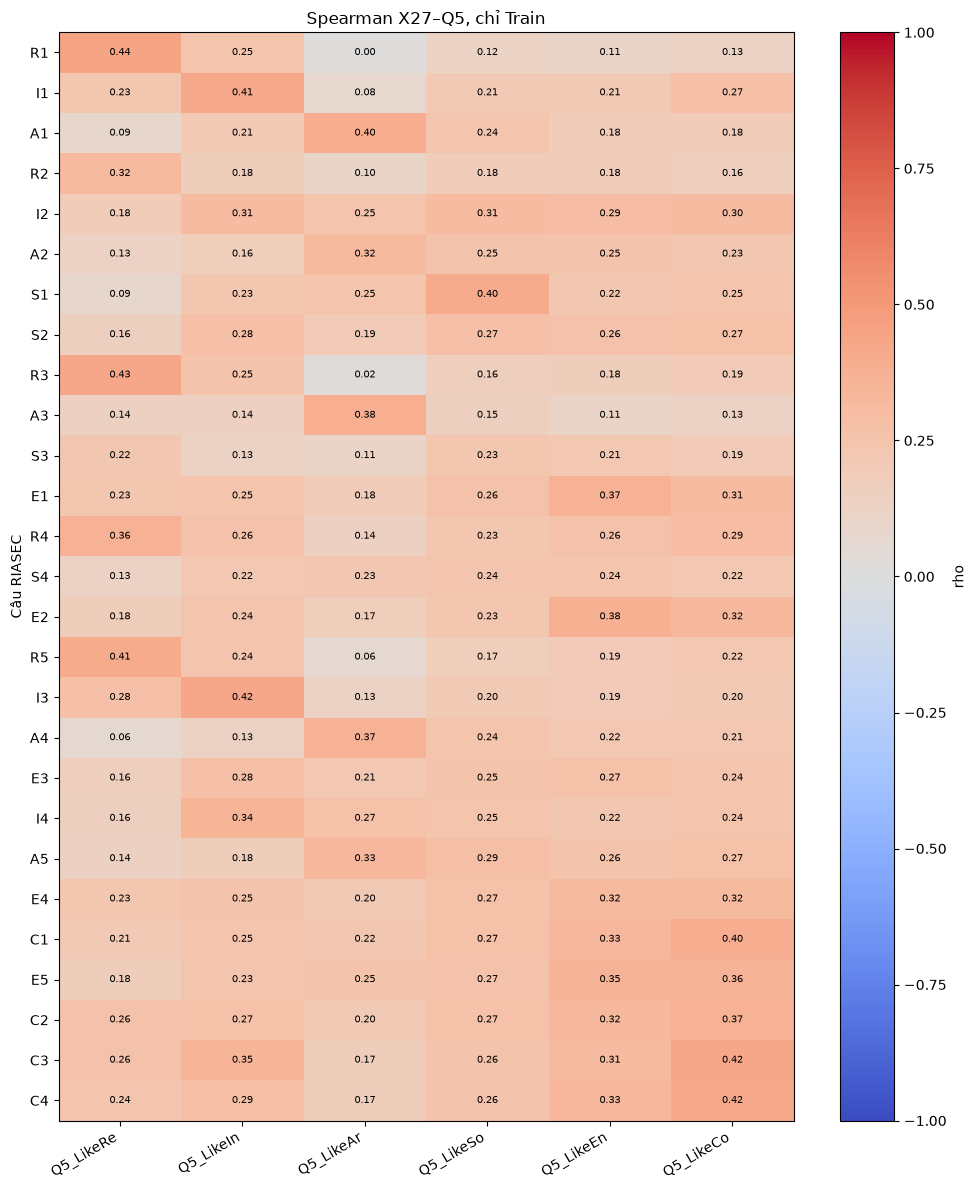

In [7]:
combined_train=X_train.join(y_train)
feature_q5_corr=combined_train.corr(method='spearman').loc[question_columns,q5_columns]
assert feature_q5_corr.shape==(27,6) and np.isfinite(feature_q5_corr.to_numpy()).all()
display(feature_q5_corr.round(4))
top_links=[]
for target in q5_columns:
    strongest=feature_q5_corr[target].abs().sort_values(ascending=False,kind='stable').head(3).index
    for question in strongest:
        top_links.append({'Q5':target,'Câu':question,'rho':feature_q5_corr.loc[question,target],
            '|rho|':abs(feature_q5_corr.loc[question,target]),'Nội dung':cb.loc[question,'NOI_DUNG_CODEBOOK']})
top_links=pd.DataFrame(top_links)
display(top_links.round(4))
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(10,12))
im=ax.imshow(feature_q5_corr,vmin=-1,vmax=1,cmap='coolwarm',aspect='auto')
ax.set_xticks(range(6),q5_columns,rotation=30,ha='right')
ax.set_yticks(range(27),question_columns)
for i in range(27):
    for j in range(6):ax.text(j,i,f'{feature_q5_corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=7)
ax.set(title='Spearman X27–Q5, chỉ Train',ylabel='Câu RIASEC')
fig.colorbar(im,ax=ax,label='rho');plt.tight_layout();plt.show()


## 5. Thử nghiệm SelectKBest trong training fold nội bộ
Thử nghiệm lựa chọn k đặc trưng tốt nhất (k=10, k=18) hoàn toàn bên trong training fold để đánh giá tính khả thi.


In [8]:
from sklearn.feature_selection import SelectKBest,f_classif
import warnings
illustration_target='Q5_LikeRe'
inner_splitter=GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=42)
inner_train_pos,inner_valid_pos=next(inner_splitter.split(X_train,groups=groups_train))
X_inner_train=X_train.iloc[inner_train_pos].copy()
X_inner_valid=X_train.iloc[inner_valid_pos].copy()
y_inner_train=y_train[illustration_target].iloc[inner_train_pos].copy()
y_inner_valid=y_train[illustration_target].iloc[inner_valid_pos].copy()
assert len(inner_train_pos)+len(inner_valid_pos)==3963
assert set(inner_train_pos).isdisjoint(inner_valid_pos)
assert X_inner_train.index.intersection(X_inner_valid.index).empty
assert set(groups_train.iloc[inner_train_pos]).isdisjoint(groups_train.iloc[inner_valid_pos])
assert set(X_inner_train.itertuples(index=False,name=None)).isdisjoint(X_inner_valid.itertuples(index=False,name=None))
assert X_inner_train.index.equals(y_inner_train.index)
assert X_inner_valid.index.equals(y_inner_valid.index)
inner_summary=pd.DataFrame({'Số dòng':[len(X_inner_train),len(X_inner_valid)],
    'Số group':[groups_train.iloc[inner_train_pos].nunique(),groups_train.iloc[inner_valid_pos].nunique()],
    'Số mức LikeRe':[y_inner_train.nunique(),y_inner_valid.nunique()]},index=['Training nội bộ','Validation nội bộ'])
display(inner_summary)
inner_support=pd.DataFrame({'Training n':y_inner_train.value_counts().reindex(range(1,6),fill_value=0),
                            'Validation n':y_inner_valid.value_counts().reindex(range(1,6),fill_value=0)})
display(inner_support)
if not inner_support.gt(0).all().all():
    raise RuntimeError('Fold thiếu mức LikeRe; báo cáo và dừng, không thử seed khác.')


                   Số dòng  Số group  Số mức LikeRe
Training nội bộ       3233      2854              5
Validation nội bộ      730       714              5

           Training n  Validation n
Q5_LikeRe                          
1                 891           201
2                 795           168
3                 882           221
4                 364            63
5                 301            77

In [9]:
selected_by_k={27:list(question_columns)}
selectors_demo={}
transformed_shapes=[]
selector_warnings=[]
for k in [10,18]:
    selector_demo=SelectKBest(score_func=f_classif,k=k)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        selector_demo.fit(X_inner_train,y_inner_train)
        training_selected=selector_demo.transform(X_inner_train)
        validation_selected=selector_demo.transform(X_inner_valid)
    for warning in caught:
        selector_warnings.append({'k':k,'Category':warning.category.__name__,'Message':str(warning.message)})
    assert selector_demo.n_features_in_==27
    assert np.array_equal(selector_demo.feature_names_in_,question_columns)
    assert np.isfinite(selector_demo.scores_).all()
    assert np.isfinite(training_selected).all() and np.isfinite(validation_selected).all()
    selected_by_k[k]=X_inner_train.columns[selector_demo.get_support()].tolist()
    assert len(selected_by_k[k])==k
    assert training_selected.shape==(len(X_inner_train),k)
    assert validation_selected.shape==(len(X_inner_valid),k)
    selectors_demo[k]=selector_demo
    transformed_shapes.append({'k':k,'Training shape':str(training_selected.shape),'Validation shape':str(validation_selected.shape)})
    print('Câu được chọn ở k='+str(k)+':',', '.join(selected_by_k[k]))
# k=27 là passthrough, không fit một selector thêm.
transformed_shapes.append({'k':27,'Training shape':str(X_inner_train.shape),'Validation shape':str(X_inner_valid.shape)})
display(pd.DataFrame(transformed_shapes))
assert np.allclose(selectors_demo[10].scores_,selectors_demo[18].scores_)
score_table=pd.DataFrame({'Câu':question_columns,'F':selectors_demo[10].scores_,
    'p-value chưa hiệu chỉnh':selectors_demo[10].pvalues_})
score_table['Chọn k=10']=score_table['Câu'].isin(selected_by_k[10])
score_table['Chọn k=18']=score_table['Câu'].isin(selected_by_k[18])
score_table['Nội dung']=score_table['Câu'].map(cb['NOI_DUNG_CODEBOOK'])
display(score_table.sort_values('F',ascending=False).round(6))
print('Số cảnh báo selector:',len(selector_warnings))
if selector_warnings:display(pd.DataFrame(selector_warnings))


Câu được chọn ở k=10: R1, R2, R3, E1, R4, R5, I3, C2, C3, C4
Câu được chọn ở k=18: R1, I1, R2, I2, R3, S3, E1, R4, E2, R5, I3, I4, E4, C1, E5, C2, C3, C4
Số cảnh báo selector: 0


    k Training shape Validation shape
0  10     (3233, 10)        (730, 10)
1  18     (3233, 18)        (730, 18)
2  27     (3233, 27)        (730, 27)

   Câu           F  p-value chưa hiệu chỉnh  Chọn k=10  Chọn k=18                                                                                                                                                                   Nội dung
0   R1  200.496163                 0.000000       True       True                      Which of the following activities did you enjoy doing when you were in lower secondary school? [I like assembling and repairing electronic equipment]
8   R3  180.161566                 0.000000       True       True               Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become an electronics engineer/electronics expert]
15  R5  167.204102                 0.000000       True       True                             Which of the following activities did you enjoy doing when you were in lower secondary school? [I want to become a mechanic/mechanical expert]
12  R4  121.335699                 0.000000       Tr

## 6. Thiết lập các cấu hình so sánh cho Công đoạn 06
Định nghĩa các phương án: giữ đủ 27 đặc trưng (k=27) so với giảm chiều (k=10, k=18) để kiểm chứng thực nghiệm bằng Cross-Validation.


In [10]:
assert X_train.equals(X_snapshot) and y_train.equals(y_snapshot)
assert X_train.shape==(3963,27) and y_train.shape==(3963,6)
assert list(X_train.columns)==question_columns and list(y_train.columns)==q5_columns
assert groups_train.nunique()==3568
assert hashlib.sha256(np.asarray(X_train.index,dtype='<i8').tobytes()).hexdigest()==train_index_sha256
assert 'X_test' not in globals() and 'y_test' not in globals()
assert 'raw_survey' not in globals() and 'survey_int' not in globals()
assert len(selected_by_k[10])==10 and len(selected_by_k[18])==18 and selected_by_k[27]==question_columns
pd.testing.assert_frame_equal(raw_codebook,original_codebook)
sha_after=hashlib.sha256(workbook_path.read_bytes()).hexdigest()
assert sha_before==sha_after
print('PASS: chỉ hai selector minh họa fit trên training nội bộ của LikeRe; validation chỉ transform, không dùng Test.')
print('PASS: đủ X27 và sáu Q5 gốc giữ nguyên, không loại mẫu hoặc chọn bộ câu cuối cùng.')
print('SHA-256 workbook:',sha_after)


PASS: chỉ hai selector minh họa fit trên training nội bộ của LikeRe; validation chỉ transform, không dùng Test.
PASS: đủ X27 và sáu Q5 gốc giữ nguyên, không loại mẫu hoặc chọn bộ câu cuối cùng.
SHA-256 workbook: c8a9445edba02a37cf862a3b1eabffba910eb7eeaf1d48b4c6f8ac19fea296c8


## 7. Đánh giá về tính toàn vẹn đặc trưng
Việc giữ nguyên đầy đủ 27 đặc trưng giúp mô hình nắm bắt trọn vẹn phổ sở thích nghề nghiệp theo chuẩn Codebook 33.


### Kết luận kỹ thuật Công đoạn 05
- 100% (27/27) câu hỏi đều có phương sai tốt (không có cột hằng, variance > 1.0).
- Không có hiện tượng dư thừa đặc trưng hay trùng lặp hoàn toàn giữa các câu hỏi.
- Quyết định giữ cấu hình k=27 (đủ 27 câu) làm phương án chuẩn cho quá trình huấn luyện mô hình.
